# Лабораторная работа №4. Решающие деревья и ансамбли моделей (Bagging, Boosting, Stacking)

**Цель работы:** изучить алгоритмы построения деревьев решений (*CART*) и основные парадигмы композиционного обучения — **Бэггинг (Bagging)**, **Градиентный бустинг (Gradient Boosting, XGBoost, LightGBM, CatBoost)** и **Стекинг (Stacking)** в задачах классификации (`csv/cl_finished.csv`) и регрессии (`csv/winequality_finished.csv`), подобрать гиперпараметры с помощью `Optuna`, а также реализовать с нуля собственные классы `CustomDecisionTree`, `CustomBagging` и `CustomStacking`.

### Структура исследования
1. **Одиночные деревья решений (`DecisionTreeClassifier`, `DecisionTreeRegressor`)** + визуализация верхних ярусов дерева (`plot_tree`).
2. **Классические ансамбли `scikit-learn`:** `Bagging`, `GradientBoosting`, `Stacking`.
3. **Современные библиотеки градиентного бустинга:** `XGBoost`, `LightGBM`, `CatBoost`.
4. **Собственные реализации с нуля:**
   * `CustomDecisionTree` (критерий Джини для классификации и дисперсия/MSE для регрессии);
   * `CustomBagging` (бутстрап-выборки + голосование большинством / усреднение);
   * `CustomStacking` (генерация Out-Of-Fold метапризнаков на кросс-валидации + обучение метамодели).

## 1. Импорт библиотек и вспомогательные функции

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mode as scipy_mode
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score
from imblearn.over_sampling import SMOTE 

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.metrics import accuracy_score, precision_score, f1_score, r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

from sklearn.ensemble import BaggingRegressor, BaggingClassifier, GradientBoostingRegressor, GradientBoostingClassifier, StackingRegressor, StackingClassifier

from sklearn.linear_model import ElasticNet, Ridge, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

from xgboost import XGBClassifier, XGBRegressor

from lightgbm import LGBMClassifier, LGBMRegressor

from catboost import CatBoostClassifier, CatBoostRegressor


from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin, clone

RANDOM_STATE = 42

class_cv = StratifiedKFold(3, shuffle = True, random_state = RANDOM_STATE)
reg_cv = KFold(3, shuffle = True, random_state = RANDOM_STATE)

C:\Users\Chaizee\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def print_metrics(true, pred, task_type):
    if task_type == "reg":
        print(f"R2: {r2_score(true, pred)}")
        print(f"MSE: {mean_squared_error(true, pred)}")
        print(f"MAE: {mean_absolute_error(true, pred)}")
        print(f"MAPE: {mean_absolute_percentage_error(true, pred)}")
        
        return
    elif task_type == "class":
        print(f"Accuracy: {accuracy_score(true, pred)}")
        print(f"Precision: {precision_score(true, pred, average='weighted', zero_division=0)}")
        print(f"F1 score: {f1_score(true, pred, average = 'weighted')}")

        return

## 2. Загрузка и подготовка наборов данных (Классификация и Регрессия)

In [3]:
class_df = pd.read_csv("csv/cl_finished.csv", sep = ";")
X_class = class_df.drop(columns = "Diabetes_012")
y_class = class_df["Diabetes_012"]

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(X_class, y_class, test_size = 0.3, stratify = y_class, random_state = RANDOM_STATE)

sm = SMOTE(random_state=RANDOM_STATE)
X_class_train_resampled, y_class_train_resampled = sm.fit_resample(X_class_train, y_class_train)

X_class_train_res, _, y_class_train_res, _ = train_test_split(X_class_train_resampled, y_class_train_resampled, train_size=10000, random_state=RANDOM_STATE)

In [4]:
regress_df = pd.read_csv("csv/winequality_finished.csv", sep = ";")
X_reg = regress_df.drop(columns = "quality")
y_reg = regress_df["quality"]

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(X_reg, y_reg, test_size = 0.3, random_state = RANDOM_STATE)

## 3. Одиночные решающие деревья (CART) и их визуализация

In [5]:

def objective_trees(trial, model_type):
    if model_type == "classification":
        max_depth = trial.suggest_int("max_depth", 2, 20)
        min_samples_split = trial.suggest_int("min_samples_split", 2, 32)
        min_samples_leaf = trial.suggest_int("min_samples_leaf", 2, 32)

        criterion = trial.suggest_categorical("criterion", ["gini", "entropy", "log_loss"])

        model = DecisionTreeClassifier(max_depth = max_depth, min_samples_split = min_samples_split, 
                                            min_samples_leaf = min_samples_leaf, criterion = criterion, random_state = RANDOM_STATE)
        
        score = cross_val_score(model, X_class_train, y_class_train, cv=class_cv, scoring="accuracy", n_jobs=-1).mean()
        
        return score

    
    if model_type == "regression":

        max_depth = trial.suggest_int("max_depth", 2, 20)
        min_samples_split = trial.suggest_int("min_samples_split", 2, 16)
        min_samples_leaf = trial.suggest_int("min_samples_leaf", 2, 16)

        criterion = trial.suggest_categorical("criterion", ['squared_error', 'friedman_mse', 'poisson'])

        model = DecisionTreeRegressor(max_depth = max_depth, min_samples_split = min_samples_split, 
                                            min_samples_leaf = min_samples_leaf, criterion = criterion, random_state = RANDOM_STATE)

        score = cross_val_score(model, X_reg_train, y_reg_train, cv = reg_cv, scoring = "neg_mean_squared_error", n_jobs=-1).mean()

        return score

In [6]:
study_class = optuna.create_study(direction = "maximize")
study_class.optimize(lambda trial: objective_trees(trial, "classification"), n_trials = 15)

best_class_tree_model = DecisionTreeClassifier(**study_class.best_params, random_state = RANDOM_STATE)
best_class_tree_model.fit(X_class_train, y_class_train)

pred = best_class_tree_model.predict(X_class_test)
print_metrics(y_class_test, pred, "class")

Accuracy: 0.8337564372234714
Precision: 0.785170013706016
F1 score: 0.784713536118605


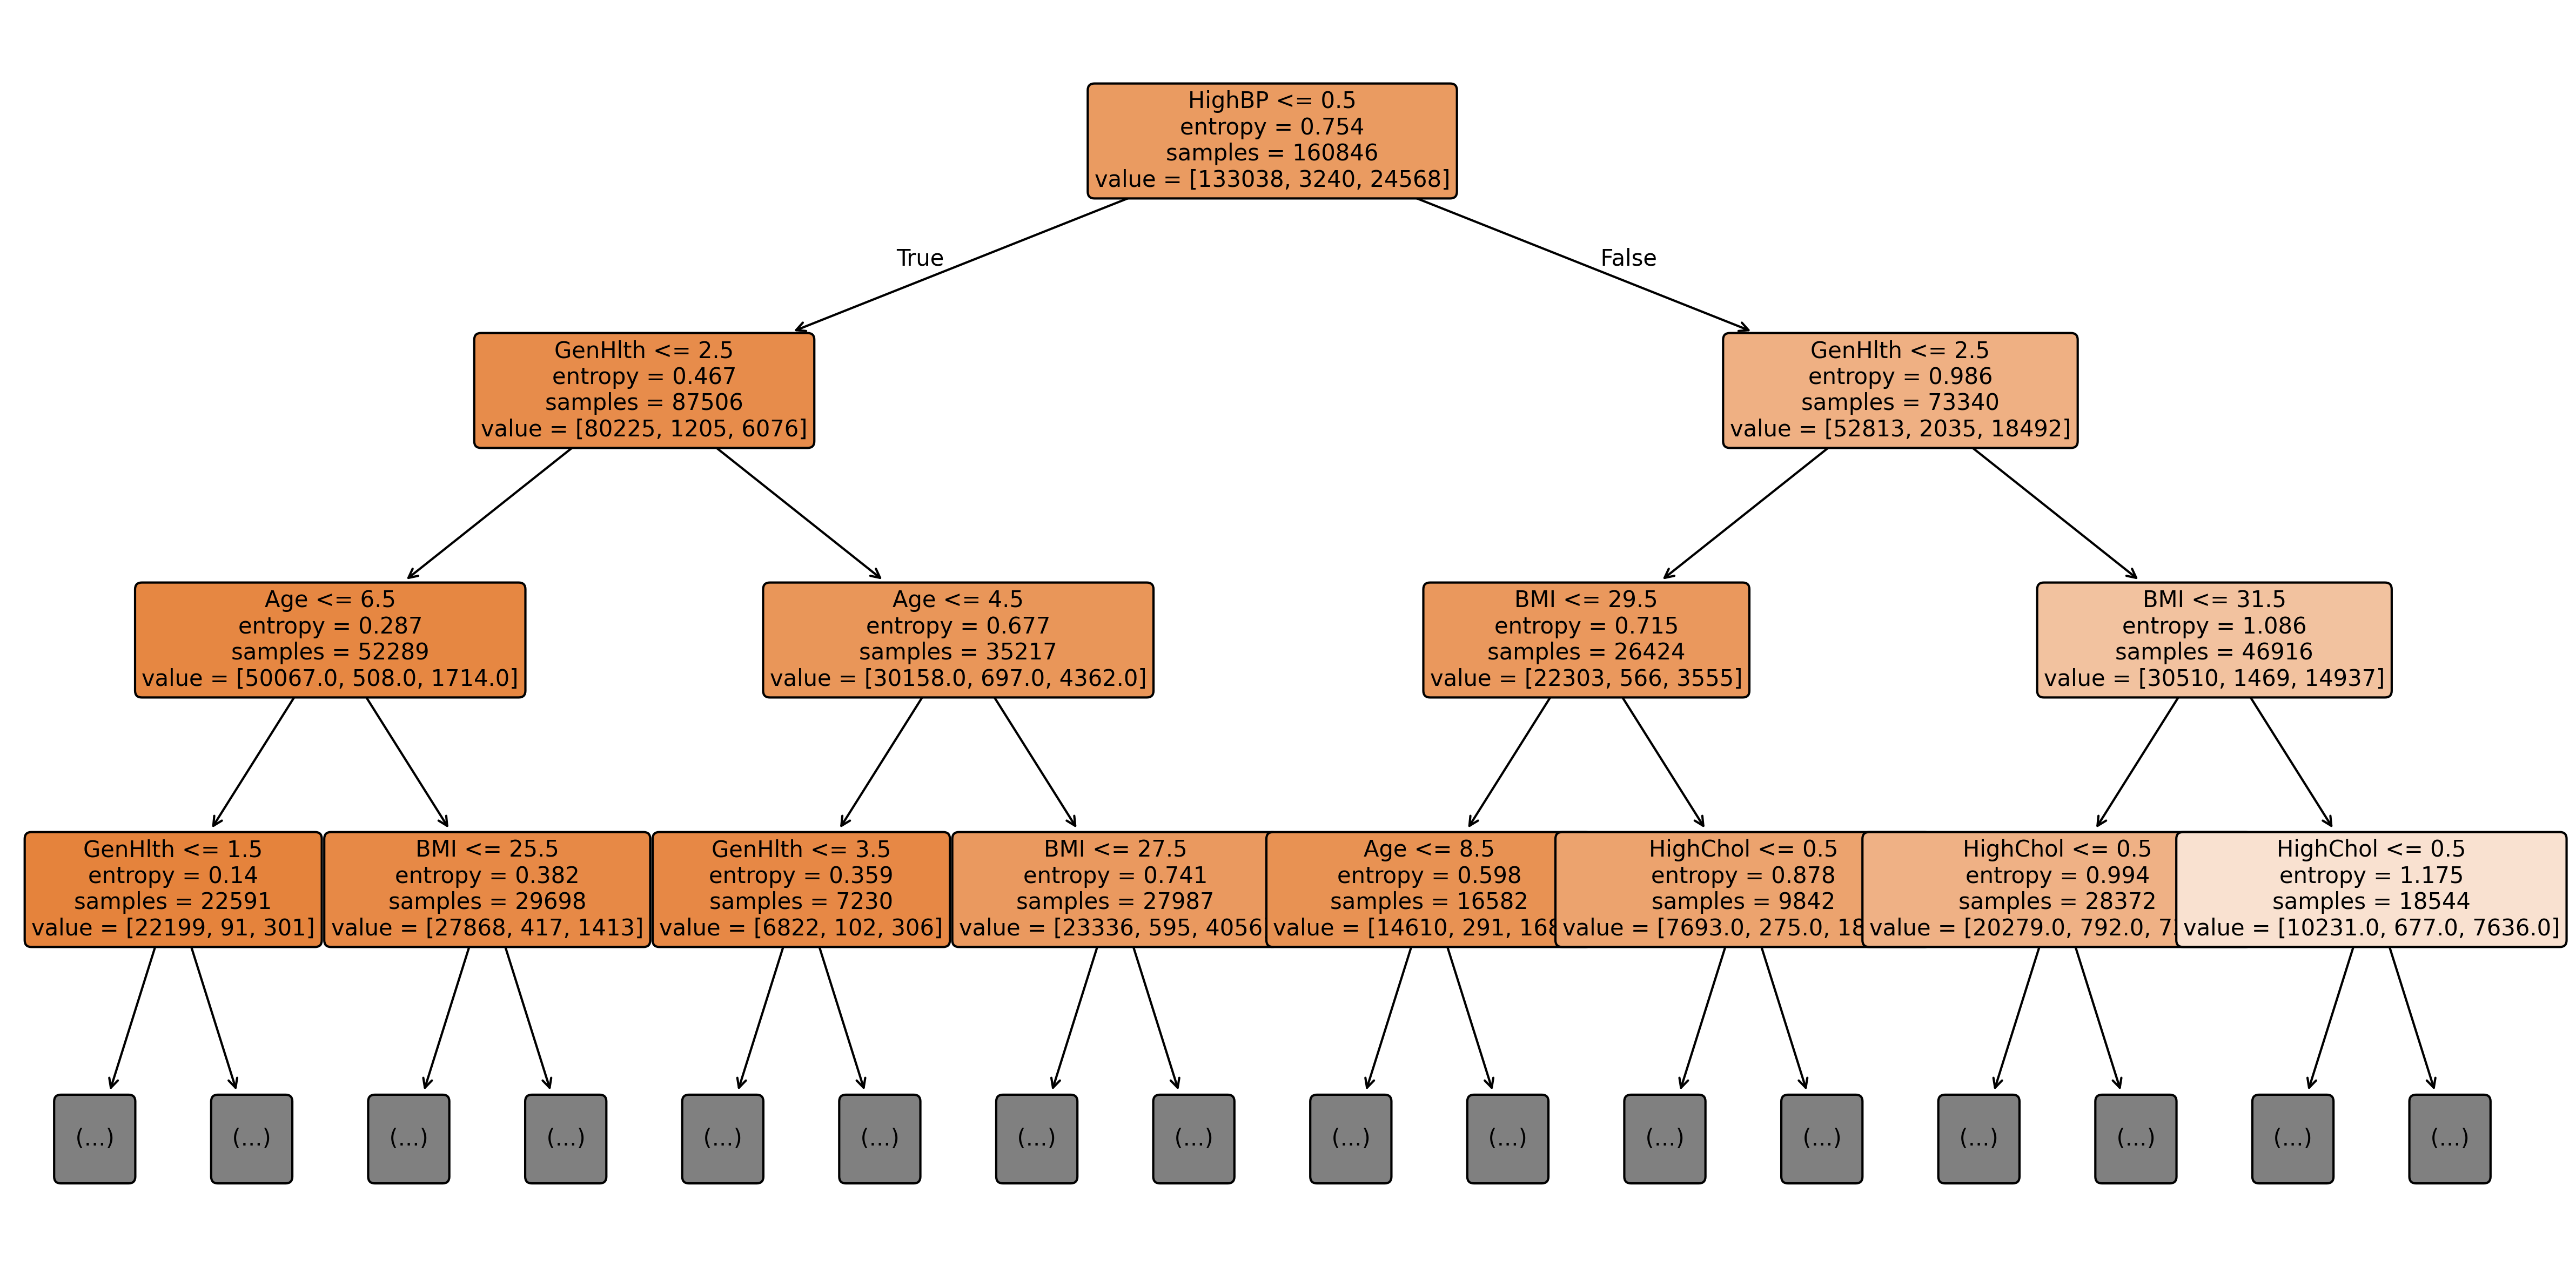

In [7]:
plt.figure(figsize=(20, 10), dpi=300)

plot_tree(
    best_class_tree_model,
    max_depth=3,
    feature_names=X_class.columns,
    filled=True,
    rounded=True,
    fontsize=10,
)

plt.show()

In [8]:
study_reg = optuna.create_study(direction = "maximize")
study_reg.optimize(lambda trial: objective_trees(trial, "regression"), n_trials = 15)

best_reg_tree_model = DecisionTreeRegressor(**study_reg.best_params, random_state = RANDOM_STATE)
best_reg_tree_model.fit(X_reg_train, y_reg_train)

pred_reg = best_reg_tree_model.predict(X_reg_test)
print_metrics(y_reg_test, pred_reg, "reg")

R2: 0.2779023693515629
MSE: 0.52687129623625
MAE: 0.5666406198308078
MAPE: 0.10175431160462299


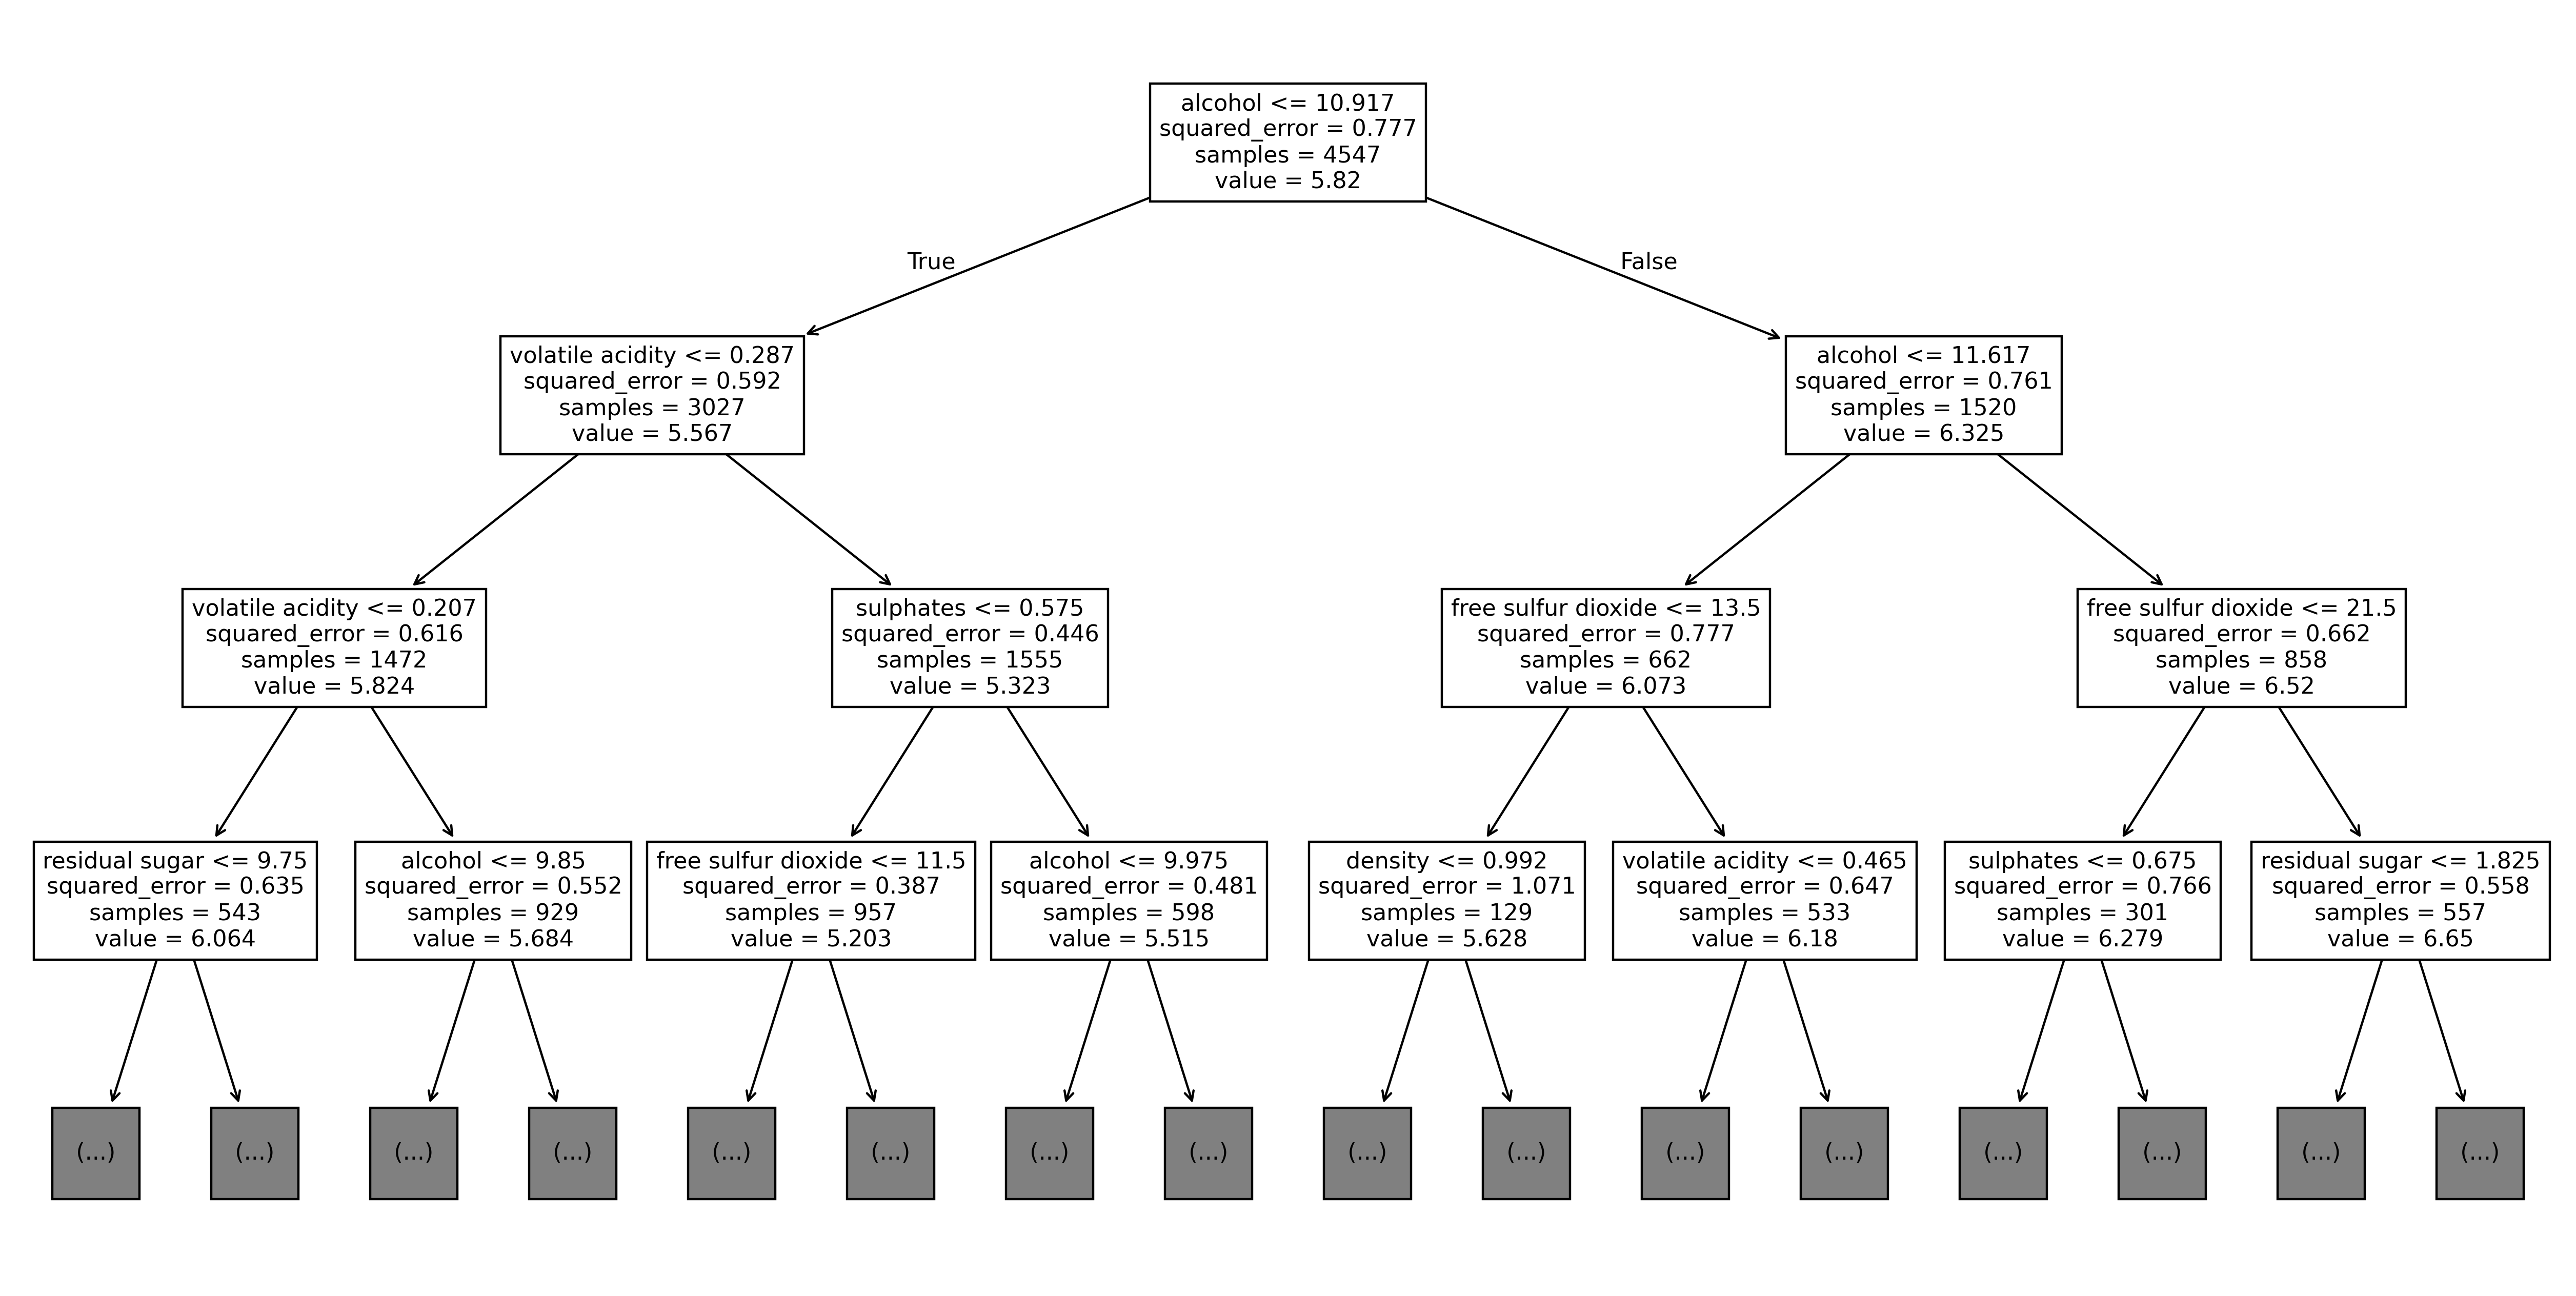

In [9]:
plt.figure(figsize = (20, 10), dpi = 320)

plot_tree(
    best_reg_tree_model,
    max_depth = 3,
    feature_names = X_reg.columns,
    fontsize = 10
)

plt.show()

## 4. Ансамбли моделей в `scikit-learn`: Bagging, Gradient Boosting, Stacking

In [10]:
def objective_ensembles(trial, model_type):
    if model_type in ["BaggingRegressor", "BaggingClassifier"]:
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 10, 35),
            "max_samples": trial.suggest_float("max_samples", 0.5, 1.0),
            "max_features": trial.suggest_float("max_features", 0.5, 1.0),
            "bootstrap": trial.suggest_categorical("bootstrap", [True, False]),
        }

        if model_type == "BaggingRegressor":
            base_tree = DecisionTreeRegressor(**study_reg.best_params, random_state = RANDOM_STATE)
            
            model = BaggingRegressor(estimator = base_tree, **params, random_state = RANDOM_STATE, n_jobs=-1)
            score = cross_val_score(model, X_reg_train, y_reg_train, cv=reg_cv, scoring="neg_mean_squared_error", n_jobs=-1).mean()

        elif model_type == "BaggingClassifier":
            base_tree = DecisionTreeClassifier(**study_class.best_params, random_state=RANDOM_STATE)

            model = BaggingClassifier(estimator=base_tree, **params, random_state=RANDOM_STATE, n_jobs=-1)
            score = cross_val_score(model, X_class_train_res, y_class_train_res, cv=class_cv, scoring="accuracy", n_jobs=-1).mean()

    elif model_type in ["GradientBoostingRegressor", "GradientBoostingClassifier"]:
        params = {
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=False),
            "n_estimators": trial.suggest_int("n_estimators", 50, 300, step=25),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "max_depth": trial.suggest_int("max_depth", 3, 6),
            "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
            "max_features": trial.suggest_categorical("max_features", ['sqrt', 'log2']),
            "n_iter_no_change": 10,
            "validation_fraction": 0.1,
        }

        if model_type == "GradientBoostingRegressor":
            params["loss"] = trial.suggest_categorical("loss", ['squared_error', 'huber'])

            model = GradientBoostingRegressor(**params, random_state=RANDOM_STATE)
            score = cross_val_score(model, X_reg_train, y_reg_train, cv=reg_cv, scoring="neg_mean_squared_error", n_jobs=-1).mean()

        elif model_type == "GradientBoostingClassifier":
            params["loss"] = "log_loss"

            model = GradientBoostingClassifier(**params, random_state=RANDOM_STATE)
            score = cross_val_score(model, X_class_train_res, y_class_train_res, cv=class_cv, scoring="accuracy", n_jobs=-1).mean()

    elif model_type in ["StackingRegressor", "StackingClassifier"]:
        
        if model_type == "StackingRegressor":
            base_estimators = [
                ("tree", DecisionTreeRegressor(**study_reg.best_params, random_state=RANDOM_STATE)),
                ("lgb", LGBMRegressor(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)),
                ("elastic", make_pipeline(StandardScaler(), ElasticNet(l1_ratio=trial.suggest_float("base_l1_ratio", 0, 0.7, step = 0.05), random_state=RANDOM_STATE)))
            ]

            meta_params = {
                "alpha": trial.suggest_float("meta_alpha", 0.01, 10.0, log=True)
            }

            final_estimator = Ridge(**meta_params)

            model = StackingRegressor(estimators=base_estimators, final_estimator=final_estimator, cv=3, n_jobs=-1)
            score = cross_val_score(model, X_reg_train, y_reg_train, cv=reg_cv, scoring="neg_mean_squared_error", n_jobs=-1).mean()

        elif model_type == "StackingClassifier":

            base_estimators = [
                ("tree", DecisionTreeClassifier(**study_class.best_params, random_state=RANDOM_STATE)),
                ("lgb", LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)),
                ("lr", make_pipeline(StandardScaler(), LogisticRegression(C=trial.suggest_float("base_C", 0.01, 10.0, log=True), max_iter=500, random_state=RANDOM_STATE)))
            ]

            meta_params = {
                "tol": trial.suggest_float("meta_tol", 1e-7, 1e-2, log=True),
                "C": trial.suggest_float("meta_C", 0.01, 10.0, log=True),
                "max_iter": 500
            }

            final_estimator = LogisticRegression(**meta_params)

            model = StackingClassifier(estimators=base_estimators, final_estimator=final_estimator, cv=3, n_jobs=-1)
            score = cross_val_score(model, X_class_train_res, y_class_train_res, cv=class_cv, scoring="accuracy", n_jobs=-1).mean()

    return score

### 4.1. Bagging (Regressor & Classifier)

In [11]:
study_bagreg = optuna.create_study(direction="maximize")
study_bagreg.optimize(lambda trial: objective_ensembles(trial, "BaggingRegressor"), n_trials=15)

best_bagreg_model = BaggingRegressor(estimator=DecisionTreeRegressor(**study_reg.best_params, random_state=RANDOM_STATE),
                                **study_bagreg.best_params, random_state=RANDOM_STATE, n_jobs=-1)
best_bagreg_model.fit(X_reg_train, y_reg_train)

bagreg_pred = best_bagreg_model.predict(X_reg_test)
print_metrics(y_reg_test, bagreg_pred, "reg")

R2: 0.36480282030626743
MSE: 0.46346525348700973
MAE: 0.5331259226016799
MAPE: 0.09589140815119943


In [12]:
study_bagclass = optuna.create_study(direction="maximize")
study_bagclass.optimize(lambda trial: objective_ensembles(trial, "BaggingClassifier"), n_trials=15, show_progress_bar=True)

best_bagclass_model = BaggingClassifier(estimator=DecisionTreeClassifier(**study_class.best_params, random_state=RANDOM_STATE),
                                         **study_bagclass.best_params, random_state=RANDOM_STATE, n_jobs=-1)
best_bagclass_model.fit(X_class_train_res, y_class_train_res)

best_bagclass_pred = best_bagclass_model.predict(X_class_test)
print_metrics(y_class_test, best_bagclass_pred, "class")

Best trial: 17. Best value: 0.5395: 100%|██████████| 25/25 [01:07<00:00,  2.68s/it]


Accuracy: 0.5928918546456807
Precision: 0.8253849800325874
F1 score: 0.6657707167386621


### 4.2. Gradient Boosting (Regressor & Classifier)

In [13]:
study_gradboost_reg = optuna.create_study(direction="maximize")
study_gradboost_reg.optimize(lambda trial: objective_ensembles(trial, "GradientBoostingRegressor"), n_trials=15, show_progress_bar=True)

best_grboost_reg_model = GradientBoostingRegressor(**study_gradboost_reg.best_params, random_state=RANDOM_STATE).fit(X_reg_train, y_reg_train)

best_grboost_reg_pred = best_grboost_reg_model.predict(X_reg_test)
print_metrics(y_reg_test, best_grboost_reg_pred, "reg")

Best trial: 17. Best value: -0.429801: 100%|██████████| 20/20 [02:00<00:00,  6.02s/it]


R2: 0.4909341457072316
MSE: 0.3714347965385133
MAE: 0.44886060870221123
MAPE: 0.08056012141372053


In [14]:
study_gradboost_class = optuna.create_study(direction="maximize")
study_gradboost_class.optimize(lambda trial: objective_ensembles(trial, "GradientBoostingClassifier"), n_trials=15, show_progress_bar=True)

best_grboost_class_model = GradientBoostingClassifier(**study_gradboost_class.best_params, random_state=RANDOM_STATE).fit(X_class_train_res, y_class_train_res)

best_grboost_class_pred = best_grboost_class_model.predict(X_class_test)
print_metrics(y_class_test, best_grboost_class_pred, "class")

Best trial: 7. Best value: 0.6109: 100%|██████████| 20/20 [02:24<00:00,  7.20s/it]


Accuracy: 0.6084137230724596
Precision: 0.7887746886894685
F1 score: 0.6732866846080103


### 4.3. Stacking (Regressor & Classifier)

In [15]:
study_stack_reg = optuna.create_study(direction="maximize")
study_stack_reg.optimize(lambda trial: objective_ensembles(trial, "StackingRegressor"), n_trials=15, show_progress_bar=True)

base_estimators_reg = [
                ("tree", DecisionTreeRegressor(**study_reg.best_params, random_state=RANDOM_STATE)),
                ("lgb", LGBMRegressor(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)),
                ("elastic", make_pipeline(StandardScaler(), ElasticNet(l1_ratio=study_stack_reg.best_params["base_l1_ratio"], random_state=RANDOM_STATE)))
            ]

meta_estimator_reg = Ridge(alpha=study_stack_reg.best_params["meta_alpha"])

best_stack_reg_model = StackingRegressor(estimators=base_estimators_reg, final_estimator=meta_estimator_reg, cv=3, n_jobs=-1).fit(X_reg_train, y_reg_train)

best_stack_reg_pred = best_stack_reg_model.predict(X_reg_test)
print_metrics(y_reg_test, best_stack_reg_pred, "reg")

Best trial: 18. Best value: -0.436472: 100%|██████████| 20/20 [01:21<00:00,  4.05s/it]


R2: 0.4495011540340207
MSE: 0.4016659634933299
MAE: 0.4874030570477557
MAPE: 0.0873734078039786


In [16]:
study_stack_class = optuna.create_study(direction="maximize")
study_stack_class.optimize(lambda trial: objective_ensembles(trial, "StackingClassifier"), n_trials=15, show_progress_bar=True)

base_estimators_class = [
                ("tree", DecisionTreeClassifier(**study_class.best_params, random_state=RANDOM_STATE)),
                ("lgb", LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)),
                ("lr", make_pipeline(StandardScaler(), LogisticRegression(C=study_stack_class.best_params["base_C"], max_iter=500, random_state=RANDOM_STATE)))
            ]

meta_estimator_class = LogisticRegression(tol=study_stack_class.best_params["meta_tol"], C=study_stack_class.best_params["meta_C"], max_iter=500)

best_stack_class_model = StackingClassifier(estimators=base_estimators_class, final_estimator=meta_estimator_class, cv=3, n_jobs=-1).fit(X_class_train_res, y_class_train_res)

best_stack_class_pred = best_stack_class_model.predict(X_class_test)
print_metrics(y_class_test, best_stack_class_pred, "class")

Best trial: 4. Best value: 0.6: 100%|██████████| 15/15 [02:15<00:00,  9.01s/it]


Accuracy: 0.6083702038151882
Precision: 0.8031320919050686
F1 score: 0.6786742330094291


## 5. Градиентный бустинг: XGBoost, LightGBM, CatBoost

In [17]:
def objective_grads(trial, boost_type):

    if boost_type in ["XGBClassifier", "XGBRegressor"]:
        params = {
            "n_estimators" : trial.suggest_int("n_estimators", 100, 400),
            "learning_rate" : trial.suggest_float("learning_rate", 0.02, 0.25),
            "max_depth" : trial.suggest_int("max_depth", 3, 8),
            "subsample" : trial.suggest_float("subsample", 0.5, 0.9),
            "min_child_weight" : trial.suggest_int("min_child_weight", 1, 20),
            "n_jobs" : -1,
        }

        if boost_type == "XGBClassifier":
            model = XGBClassifier(**params, random_state=RANDOM_STATE, objective="multi:softprob", num_class=3)
            score = cross_val_score(model, X_class_train_res, y_class_train_res, cv=class_cv, scoring="accuracy", n_jobs=-1).mean()

        elif boost_type == "XGBRegressor":
            model = XGBRegressor(**params, random_state=RANDOM_STATE)
            score = cross_val_score(model, X_reg_train, y_reg_train, cv=reg_cv, scoring="neg_mean_squared_error", n_jobs=-1).mean()

        return score
    
    if boost_type in ["LGBMClassifier", "LGBMRegressor"]:
        params = {
            "num_leaves" : trial.suggest_int("num_leaves", 15, 127),
            "n_estimators" : trial.suggest_int("n_estimators", 100, 400),
            "learning_rate" : trial.suggest_float("learning_rate", 0.02, 0.2),
            "max_depth" : trial.suggest_int("max_depth", 3, 8),
            "subsample" : trial.suggest_float("subsample", 0.5, 0.9),
            "min_child_samples" : trial.suggest_int("min_child_samples", 30, 150),
            "verbose" : -1,
            "n_jobs" : -1,
        }

        if boost_type == "LGBMClassifier":
            model = LGBMClassifier(**params, random_state=RANDOM_STATE, objective="multiclass", num_class=3)
            score = cross_val_score(model, X_class_train_res, y_class_train_res, cv=class_cv, scoring="accuracy", n_jobs=-1).mean()

        elif boost_type == "LGBMRegressor":
            model = LGBMRegressor(**params, random_state=RANDOM_STATE)
            score = cross_val_score(model, X_reg_train, y_reg_train, cv=reg_cv, scoring="neg_mean_squared_error", n_jobs=-1).mean()

        return score
    
    if boost_type in ["CatBoostClassifier", "CatBoostRegressor"]:
        params = {
            "iterations": trial.suggest_int("iterations", 150, 400),
            "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2),
            "depth": trial.suggest_int("depth", 4, 7),
            "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 10),
            "random_strength": trial.suggest_float("random_strength", 1e-9, 10, log=True),
            "verbose": 0,
            "allow_writing_files": False,
            "thread_count": -1,
        }

        if boost_type == "CatBoostClassifier":
            model = CatBoostClassifier(**params, random_seed=RANDOM_STATE, loss_function="MultiClass")
            score = cross_val_score(model, X_class_train_res, y_class_train_res, cv=class_cv, scoring="accuracy", n_jobs=-1).mean()

        elif boost_type == "CatBoostRegressor":
            model = CatBoostRegressor(**params, random_seed=RANDOM_STATE)
            score = cross_val_score(model, X_reg_train, y_reg_train, cv=reg_cv, scoring="neg_mean_squared_error", n_jobs=-1).mean()
            
        return score

### 5.1. XGBoost (`XGBClassifier`, `XGBRegressor`)

In [18]:
study_xgb_class = optuna.create_study(direction="maximize")
study_xgb_class.optimize(lambda trial: objective_grads(trial, "XGBClassifier"), n_trials=10, show_progress_bar=True)

best_xgb_class_model = XGBClassifier(**study_xgb_class.best_params, n_jobs=-1, random_state=RANDOM_STATE).fit(X_class_train_res, y_class_train_res)

best_xgb_class_pred = best_xgb_class_model.predict(X_class_test)
print_metrics(y_class_test, best_xgb_class_pred, "class")

Best trial: 3. Best value: 0.6286: 100%|██████████| 10/10 [00:18<00:00,  1.83s/it]


Accuracy: 0.601653731776311
Precision: 0.786534104420256
F1 score: 0.6678491394161984


In [19]:
study_xgb_reg = optuna.create_study(direction="maximize")
study_xgb_reg.optimize(lambda trial: objective_grads(trial, "XGBRegressor"), n_trials=10, show_progress_bar=True)

best_xgb_reg_model = XGBRegressor(**study_xgb_reg.best_params, n_jobs=-1, random_state=RANDOM_STATE).fit(X_reg_train, y_reg_train)

best_xgb_reg_pred = best_xgb_reg_model.predict(X_reg_test)
print_metrics(y_reg_test, best_xgb_reg_pred, "reg")

Best trial: 9. Best value: -0.430744: 100%|██████████| 10/10 [00:08<00:00,  1.18it/s]


R2: 0.4908106327056885
MSE: 0.3715249300003052
MAE: 0.41063496470451355
MAPE: 0.07410530000925064


### 5.2. LightGBM (`LGBMClassifier`, `LGBMRegressor`)

In [20]:
study_lgbm_class = optuna.create_study(direction="maximize")
study_lgbm_class.optimize(lambda trial: objective_grads(trial, "LGBMClassifier"), n_trials=10, show_progress_bar=True)

best_lgbm_class_model = LGBMClassifier(**study_lgbm_class.best_params, verbose=-1, n_jobs=-1, random_state=RANDOM_STATE).fit(X_class_train_res, y_class_train_res)

best_lgbm_class_pred = best_lgbm_class_model.predict(X_class_test)
print_metrics(y_class_test, best_lgbm_class_pred, "class")

Best trial: 8. Best value: 0.6221: 100%|██████████| 10/10 [00:21<00:00,  2.14s/it]


Accuracy: 0.5870457677522304
Precision: 0.7825897591928005
F1 score: 0.6558822223215609


In [21]:
study_lgbm_reg = optuna.create_study(direction="maximize")
study_lgbm_reg.optimize(lambda trial: objective_grads(trial, "LGBMRegressor"), n_trials=10, show_progress_bar=True)

best_lgbm_reg_model = LGBMRegressor(**study_lgbm_reg.best_params, verbose=-1, n_jobs=-1, random_state=RANDOM_STATE).fit(X_reg_train, y_reg_train)

best_lgbm_reg_pred = best_lgbm_reg_model.predict(X_reg_test)
print_metrics(y_reg_test, best_lgbm_reg_pred, "reg")

Best trial: 7. Best value: -0.437015: 100%|██████████| 10/10 [00:07<00:00,  1.34it/s]


R2: 0.4563347232724675
MSE: 0.39667991821390214
MAE: 0.4648883013185898
MAPE: 0.0836795273818006


### 5.3. CatBoost (`CatBoostClassifier`, `CatBoostRegressor`)

In [22]:
study_cat_class = optuna.create_study(direction="maximize")
study_cat_class.optimize(lambda trial: objective_grads(trial, "CatBoostClassifier"), n_trials=10, show_progress_bar=True)

best_cat_class_model = CatBoostClassifier(**study_cat_class.best_params, random_state=RANDOM_STATE, verbose=0, allow_writing_files=False).fit(X_class_train_res, y_class_train_res)

best_cat_class_pred = best_cat_class_model.predict(X_class_test)
print_metrics(y_class_test, best_cat_class_pred, "class")

Best trial: 5. Best value: 0.6279: 100%|██████████| 10/10 [00:34<00:00,  3.41s/it]


Accuracy: 0.6105461666787554
Precision: 0.7955320033976184
F1 score: 0.6771433339228776


In [23]:
study_cat_reg = optuna.create_study(direction="maximize")
study_cat_reg.optimize(lambda trial: objective_grads(trial, "CatBoostRegressor"), n_trials=10, show_progress_bar=True)

best_cat_reg_model = CatBoostRegressor(**study_cat_reg.best_params, random_state=RANDOM_STATE, verbose=0, allow_writing_files=False).fit(X_reg_train, y_reg_train)

best_cat_reg_pred = best_cat_reg_model.predict(X_reg_test)
print_metrics(y_reg_test, best_cat_reg_pred, "reg")

Best trial: 5. Best value: -0.406301: 100%|██████████| 10/10 [00:19<00:00,  1.92s/it]


R2: 0.5116332776122032
MSE: 0.35633188247972575
MAE: 0.4222397943047612
MAPE: 0.07601217334094104


## 6. Собственная реализация дерева решений (`CustomDecisionTree`)
Реализуем алгоритм рекурсивного бинарного разбиения **CART**:
* Для **классификации** минимизируется взвешенная неопределённость Джини дочерних узлов: $G(S) = 1 - \sum_{k} p_k^2$;
* Для **регрессии** минимизируется взвешенная среднеквадратичная ошибка (дисперсия) дочерних узлов: $MSE(S) = \frac{1}{|S|} \sum (y_i - \bar{y}_S)^2$.

In [24]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf(self):
        return self.value is not None

class CustomDecisionTree(BaseEstimator):
    def __init__(self, max_depth=None, min_samples_split=2, task="classification"):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.task = task
        self.root = None
    
    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y)

        if self.task == "classification":
            self.classes_ = np.unique(y)

        self.root = self._build_tree(X, y, depth=0)
        return self
        
    def _build_tree(self, X, y, depth):
        num_samples, num_features = X.shape
        
        if (self.max_depth is not None and depth >= self.max_depth) or \
        (num_samples < self.min_samples_split) or \
        (len(np.unique(y)) == 1):
            return Node(value=self._calculate_leaf_value(y))
        
        best_feat, best_thresh = self._best_split(X, y, num_features)

        if best_feat is None:
            return Node(value=self._calculate_leaf_value(y))
        
        left_idx = X[:, best_feat] <= best_thresh
        right_idx = ~left_idx

        left_child = self._build_tree(X[left_idx], y[left_idx], depth + 1)
        right_child = self._build_tree(X[right_idx], y[right_idx], depth + 1)

        return Node(feature=best_feat, threshold=best_thresh, left=left_child, right=right_child)
    
    def _best_split(self, X, y, num_features):

        best_gain = -1.0 if self.task == "classification" else float("inf")
        best_feat, best_thresh = None, None

        current_impurity = self._impurity(y)
        n = len(y)

        for feat_idx in range(num_features):
            X_column = X[:, feat_idx]

            thresholds = np.unique(X_column)
            if len(thresholds) > 20:
                thresholds = np.unique(np.percentile(X_column, np.linspace(5, 95, 20)))

            for threshold in thresholds:
                left_idx = X_column <= threshold
                right_idx = ~left_idx

                n_l, n_r = np.sum(left_idx), np.sum(right_idx)
                if n_l == 0 or n_r == 0:
                    continue

                left_impurity = self._impurity(y[left_idx])
                right_impurity = self._impurity(y[right_idx])

                child_impurity = (n_l / n) * left_impurity + (n_r / n) * right_impurity

                if self.task == "classification":
                    gain = current_impurity - child_impurity
                    if gain > best_gain:
                        best_gain = gain
                        best_feat = feat_idx
                        best_thresh = threshold
                else:
                    if child_impurity < best_gain:
                        best_gain = child_impurity
                        best_feat = feat_idx
                        best_thresh = threshold
        return best_feat, best_thresh
    
    def _impurity(self, y):
        if len(y) == 0:
            return 0.0
        
        if self.task == "classification":
            _, counts = np.unique(y, return_counts=True)
            probabilities = counts / len(y)
            return 1.0 - np.sum(probabilities ** 2)
        
        else:
            return np.mean((y - np.mean(y)) ** 2)
        
    def _calculate_leaf_value(self, y):
        if len(y) == 0:
            return 0.0
        
        if self.task == "classification":
            vals, counts = np.unique(y, return_counts=True)
            return vals[np.argmax(counts)]
        
        else:
            return np.mean(y)
        
    def predict(self, X):
        X = np.asarray(X, dtype=np.float64)
        return np.array([self._traverse_tree(x, self.root) for x in X])
    
    def _traverse_tree(self, x, node):
        if node.is_leaf():
            return node.value
        
        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)
    

class CustomDecisionTreeClassifier(CustomDecisionTree, ClassifierMixin):
    def __init__(self, max_depth=None, min_samples_split=2):
        super().__init__(max_depth=max_depth, min_samples_split=min_samples_split, task="classification")

class CustomDecisionTreeRegressor(CustomDecisionTree, RegressorMixin):
    def __init__(self, max_depth=None, min_samples_split=2):
        super().__init__(max_depth=max_depth, min_samples_split=min_samples_split, task="regression")

In [25]:
def objective_CustomTrees(trial, model_type):
    if model_type == "class":
        max_depth = trial.suggest_int("max_depth", 2, 12)
        min_samples_split = trial.suggest_int("min_samples_split", 2, 32)

        model = CustomDecisionTreeClassifier(max_depth = max_depth, min_samples_split = min_samples_split)
        
        score = cross_val_score(model, X_class_train_res, y_class_train_res, cv=class_cv, scoring="accuracy", n_jobs=-1).mean()
        
        return score

    
    if model_type == "reg":

        max_depth = trial.suggest_int("max_depth", 2, 12)
        min_samples_split = trial.suggest_int("min_samples_split", 2, 16)

        model = CustomDecisionTreeRegressor(max_depth = max_depth, min_samples_split = min_samples_split)

        score = cross_val_score(model, X_reg_train, y_reg_train, cv = reg_cv, scoring = "neg_mean_squared_error", n_jobs=-1).mean()

        return score

In [26]:
study_cust_class = optuna.create_study(direction = "maximize")
study_cust_class.optimize(lambda trial: objective_CustomTrees(trial, "class"), n_trials = 10, show_progress_bar=True)

best_cust_class_model = CustomDecisionTreeClassifier(**study_cust_class.best_params)
best_cust_class_model.fit(X_class_train, y_class_train)

pred_cust_class = best_cust_class_model.predict(X_class_test)
print_metrics(y_class_test, pred_cust_class, "class")

Best trial: 10. Best value: 0.529: 100%|██████████| 20/20 [03:07<00:00,  9.39s/it]


Accuracy: 0.7390150141437586
Precision: 0.7538834245500292
F1 score: 0.7461891224507694


In [27]:
study_cust_reg = optuna.create_study(direction = "maximize")
study_cust_reg.optimize(lambda trial: objective_CustomTrees(trial, "reg"), n_trials = 10, show_progress_bar=True)

best_cust_reg_model = CustomDecisionTreeRegressor(**study_cust_reg.best_params)
best_cust_reg_model.fit(X_reg_train, y_reg_train)

pred_cust_reg = best_cust_reg_model.predict(X_reg_test)
print_metrics(y_reg_test, pred_cust_reg, "reg")

Best trial: 19. Best value: -0.552557: 100%|██████████| 20/20 [05:01<00:00, 15.06s/it]


R2: 0.27022866628533215
MSE: 0.5324703367396877
MAE: 0.575840929572523
MAPE: 0.10342228089964606


## 7. Собственная реализация Бэггинга (`CustomBagging`)
Формирует $M$ бутстрап-выборок (с возвращением), обучает независимые базовые модели `CustomDecisionTree` и агрегирует их ответы усреднением (для регрессии) либо мажоритарным голосованием `scipy.stats.mode` (для классификации).

In [28]:
class CustomBagging:
    def __init__(self, base_estimator, n_estimators=10):
        self.base_estimator = base_estimator
        self.n_estimators = n_estimators
        self.models = []

    def fit(self, X, y):
        self.models = []
        n_samples = X.shape[0]

        for _ in range(self.n_estimators):
            indices = np.random.choice(n_samples, size=n_samples, replace=True)
            X_bootstrap = X[indices]
            y_bootstrap = y[indices]

            model = clone(self.base_estimator)
            model.fit(X_bootstrap, y_bootstrap)
            self.models.append(model)
        
        return self
    
    def predict(self, X, mode="reg"):
        all_preds = np.array([model.predict(X) for model in self.models])

        if mode == "reg":
            return np.mean(all_preds, axis=0)
        
        elif mode == "class":
            final_preds, _ = scipy_mode(all_preds, axis=0)
            return final_preds.ravel()

In [29]:
def objective_CustomBagging(trial, model_type):
    max_depth = trial.suggest_int("tree_max_depth", 2, 8)
    n_estimators = trial.suggest_int("bag_n_estimators", 5, 15)

    if model_type == "class":
        min_samples_split = trial.suggest_int("tree_min_samples_split", 5, 32)
        base_tree = CustomDecisionTreeClassifier(max_depth=max_depth, min_samples_split=min_samples_split)
        
        X_data = np.asarray(X_class_train_res)
        y_data = np.asarray(y_class_train_res)
        
        scores = [
            accuracy_score(
                y_data[val_idx], 
                CustomBagging(base_estimator=base_tree, n_estimators=n_estimators)
                .fit(X_data[train_idx], y_data[train_idx])
                .predict(X_data[val_idx], mode="class")
            )
            for train_idx, val_idx in class_cv.split(X_data, y_data)
        ]
        return np.mean(scores)

    if model_type == "reg":
        min_samples_split = trial.suggest_int("tree_min_samples_split", 5, 16)
        base_tree = CustomDecisionTreeRegressor(max_depth=max_depth, min_samples_split=min_samples_split)
        
        X_data = np.asarray(X_reg_train)
        y_data = np.asarray(y_reg_train)

        scores = [
            -mean_squared_error(
                y_data[val_idx], 
                CustomBagging(base_estimator=base_tree, n_estimators=n_estimators)
                .fit(X_data[train_idx], y_data[train_idx])
                .predict(X_data[val_idx], mode="reg")
            )
            for train_idx, val_idx in reg_cv.split(X_data, y_data)
        ]
        return np.mean(scores)

In [30]:
study_cust_bag_class = optuna.create_study(direction="maximize")
study_cust_bag_class.optimize(lambda trial: objective_CustomBagging(trial, "class"), n_trials=10, show_progress_bar=True)

params_class = study_cust_bag_class.best_params
tree_params_class = {
    "max_depth": params_class["tree_max_depth"],
    "min_samples_split": params_class["tree_min_samples_split"]
}

best_base_tree_class = CustomDecisionTreeClassifier(**tree_params_class)
best_cust_bag_class_model = CustomBagging(
    base_estimator=best_base_tree_class, 
    n_estimators=params_class["bag_n_estimators"]
)

best_cust_bag_class_model.fit(X_class_train_res.values, y_class_train_res.values)

pred_cust_bag_class = best_cust_bag_class_model.predict(X_class_test.values, mode="class")
print_metrics(y_class_test, pred_cust_bag_class, "class")

Best trial: 1. Best value: 0.5621: 100%|██████████| 20/20 [11:19<00:00, 33.99s/it]


Accuracy: 0.5572931021977225
Precision: 0.8235289426194018
F1 score: 0.6440557083683488


In [31]:
study_cust_bag_reg = optuna.create_study(direction="maximize")
study_cust_bag_reg.optimize(lambda trial: objective_CustomBagging(trial, "reg"), n_trials=10, show_progress_bar=True)

params_reg = study_cust_bag_reg.best_params
tree_params_reg = {
    "max_depth": params_reg["tree_max_depth"],
    "min_samples_split": params_reg["tree_min_samples_split"]
}

best_base_tree_reg = CustomDecisionTreeRegressor(**tree_params_reg)
best_cust_bag_reg_model = CustomBagging(
    base_estimator=best_base_tree_reg, 
    n_estimators=params_reg["bag_n_estimators"]
)

best_cust_bag_reg_model.fit(X_reg_train.values, y_reg_train.values)

pred_cust_bag_reg = best_cust_bag_reg_model.predict(X_reg_test.values, mode="reg")
print_metrics(y_reg_test, pred_cust_bag_reg, "reg")

Best trial: 11. Best value: -0.451517: 100%|██████████| 20/20 [43:05<00:00, 129.28s/it]


R2: 0.4209654729766471
MSE: 0.42248673706958667
MAE: 0.5015941373820307
MAPE: 0.0901321309254452


## 8. Собственная реализация Стекинга (`CustomStacking`)
Чтобы избежать утечки целевой переменной при обучении метамодели, матрица метапризнаков формируется по схеме **Out-Of-Fold (OOF)** на $K$-кратной кросс-валидации, после чего базовые алгоритмы переобучаются на всей обучающей выборке.

In [32]:
class CustomStacking:
    def __init__(self, base_models, meta_model, n_folds=5, mode="regression"):
        self.base_models = base_models
        self.meta_model = meta_model
        self.n_folds = n_folds
        self.mode = mode
        self.fitted_base_models = []

    def fit(self, X, y):

        X = np.asarray(X)
        y = np.asarray(y)
        
        self.fitted_base_models = []
        n_samples = X.shape[0]
        n_models = len(self.base_models)
        
        if self.mode == "classification":
            kf = StratifiedKFold(n_splits=self.n_folds, shuffle=True, random_state=42)
            self.classes_ = np.unique(y)
            n_classes = len(self.classes_)

            oof_features = np.zeros((n_samples, n_models * n_classes))
        else:
            kf = KFold(n_splits=self.n_folds, shuffle=True, random_state=42)
            oof_features = np.zeros((n_samples, n_models))

        for model_idx, model in enumerate(self.base_models):
            for train_idx, val_idx in kf.split(X, y):
                X_train_f, y_train_f = X[train_idx], y[train_idx]
                X_val_f = X[val_idx]
                
                fold_model = clone(model)
                fold_model.fit(X_train_f, y_train_f)
                
                if self.mode == "classification":
                    if hasattr(fold_model, "predict_proba"):
                        preds = fold_model.predict_proba(X_val_f)
                    else:
                        hard_preds = fold_model.predict(X_val_f)
                        preds = np.zeros((len(hard_preds), n_classes))
                        for i, cls in enumerate(self.classes_):
                            preds[hard_preds == cls, i] = 1.0
                            
                    start_col = model_idx * n_classes
                    end_col = start_col + n_classes
                    oof_features[val_idx, start_col:end_col] = preds
                else:
                    oof_features[val_idx, model_idx] = fold_model.predict(X_val_f)
        
        self.meta_model.fit(oof_features, y)
        
        for model in self.base_models:
            final_model = clone(model)
            final_model.fit(X, y)
            self.fitted_base_models.append(final_model)
            
        return self

    def _generate_meta_features(self, X):
        X = np.asarray(X)
        if self.mode == "classification":
            n_classes = len(self.classes_)
            meta_features = np.zeros((X.shape[0], len(self.base_models) * n_classes))
            for model_idx, model in enumerate(self.fitted_base_models):
                if hasattr(model, "predict_proba"):
                    preds = model.predict_proba(X)
                else:
                    hard_preds = model.predict(X)
                    preds = np.zeros((len(hard_preds), n_classes))
                    for i, cls in enumerate(self.classes_):
                        preds[hard_preds == cls, i] = 1.0
                        
                start_col = model_idx * n_classes
                end_col = start_col + n_classes
                meta_features[:, start_col:end_col] = preds
        else:
            meta_features = np.column_stack([
                model.predict(X) for model in self.fitted_base_models
            ])
        return meta_features

    def predict(self, X):
        meta_features = self._generate_meta_features(X)
        return self.meta_model.predict(meta_features)

    def predict_proba(self, X):
        meta_features = self._generate_meta_features(X)
        if hasattr(self.meta_model, "predict_proba"):
            return self.meta_model.predict_proba(meta_features)


In [33]:
def objective_CustomStacking(trial, model_type):
    if model_type == "class":
        tree_max_depth = trial.suggest_int("tree_max_depth", 2, 10)
        tree_min_samples_split = trial.suggest_int("tree_min_samples_split", 2, 32)
        
        base_tree = CustomDecisionTreeClassifier(
            max_depth=tree_max_depth, 
            min_samples_split=tree_min_samples_split
        )
        
        knn_neighbors = trial.suggest_int("knn_neighbors", 3, 20)
        knn_weights = trial.suggest_categorical("knn_weights", ["uniform", "distance"])
        base_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=knn_neighbors, weights=knn_weights, n_jobs=-1))
        
        base_models = [base_tree, base_knn]
        
        meta_C = trial.suggest_float("meta_C", 1e-3, 10.0, log=True)
        meta_model = LogisticRegression(C=meta_C, solver="lbfgs", max_iter=500, random_state=RANDOM_STATE)
        
        X_data = np.asarray(X_class_train_res)
        y_data = np.asarray(y_class_train_res)
        
        scores = []
        
        for train_idx, val_idx in class_cv.split(X_data, y_data):
            X_tr, y_tr = X_data[train_idx], y_data[train_idx]
            X_va, y_va = X_data[val_idx], y_data[val_idx]
            
            model = CustomStacking(
                base_models=base_models,
                meta_model=meta_model,
                n_folds=3,
                mode="classification"
            )
            model.fit(X_tr, y_tr)
            
            preds = model.predict(X_va)
            scores.append(accuracy_score(y_va, preds))
            
        return np.mean(scores)

    if model_type == "reg":
        tree_max_depth = trial.suggest_int("tree_max_depth", 2, 10)
        tree_min_samples_split = trial.suggest_int("tree_min_samples_split", 2, 16)
        
        base_tree = CustomDecisionTreeRegressor(
            max_depth=tree_max_depth, 
            min_samples_split=tree_min_samples_split
        )
        
        knn_neighbors = trial.suggest_int("knn_neighbors", 3, 20)
        knn_weights = trial.suggest_categorical("knn_weights", ["uniform", "distance"])
        base_knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=knn_neighbors, weights=knn_weights, n_jobs=-1))
        
        base_models = [base_tree, base_knn]
        
        meta_alpha = trial.suggest_float("meta_alpha", 1e-3, 100.0, log=True)
        meta_model = Ridge(alpha=meta_alpha)
        
        X_data = np.asarray(X_reg_train)
        y_data = np.asarray(y_reg_train)
        
        scores = []
        
        for train_idx, val_idx in reg_cv.split(X_data, y_data):
            X_tr, y_tr = X_data[train_idx], y_data[train_idx]
            X_va, y_va = X_data[val_idx], y_data[val_idx]
            
            model = CustomStacking(
                base_models=base_models,
                meta_model=meta_model,
                n_folds=3,
                mode="regression"
            )
            model.fit(X_tr, y_tr)
            
            preds = model.predict(X_va)
            scores.append(-mean_squared_error(y_va, preds))
            
        return np.mean(scores)


In [34]:
study_cust_stack_class = optuna.create_study(direction="maximize")
study_cust_stack_class.optimize(lambda trial: objective_CustomStacking(trial, "class"), n_trials=10, show_progress_bar=True)

best_params_class = study_cust_stack_class.best_params

tree_params_class = {
    "max_depth": best_params_class["tree_max_depth"],
    "min_samples_split": best_params_class["tree_min_samples_split"]
}

best_base_tree_class = CustomDecisionTreeClassifier(**tree_params_class)
best_base_knn_class = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors=best_params_class["knn_neighbors"],
        weights=best_params_class["knn_weights"],
        n_jobs=-1
    )
)
base_models_class = [best_base_tree_class, best_base_knn_class]

best_meta_model_class = LogisticRegression(
    C=best_params_class["meta_C"], 
    solver="lbfgs",
    max_iter=500,
    random_state=RANDOM_STATE
)

final_stack_class_model = CustomStacking(
    base_models=base_models_class,
    meta_model=best_meta_model_class,
    n_folds=3,
    mode="classification"
)
final_stack_class_model.fit(X_class_train_res.values, y_class_train_res.values)

pred_stack_class = final_stack_class_model.predict(X_class_test.values)

print_metrics(y_class_test, pred_stack_class, "class")


Best trial: 13. Best value: 0.612: 100%|██████████| 20/20 [11:34<00:00, 34.74s/it] 


Accuracy: 0.5676651918473925
Precision: 0.7966524212934609
F1 score: 0.6449344192424719


In [35]:
study_cust_stack_reg = optuna.create_study(direction="maximize")
study_cust_stack_reg.optimize(lambda trial: objective_CustomStacking(trial, "reg"), n_trials=10, show_progress_bar=True)

best_params_reg = study_cust_stack_reg.best_params

tree_params_reg = {
    "max_depth": best_params_reg["tree_max_depth"],
    "min_samples_split": best_params_reg["tree_min_samples_split"]
}

best_base_tree_reg = CustomDecisionTreeRegressor(**tree_params_reg)
best_base_knn_reg = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(
        n_neighbors=best_params_reg["knn_neighbors"],
        weights=best_params_reg["knn_weights"],
        n_jobs=-1
    )
)
base_models_reg = [best_base_tree_reg, best_base_knn_reg]

best_meta_model_reg = Ridge(alpha=best_params_reg["meta_alpha"])

final_stack_reg_model = CustomStacking(
    base_models=base_models_reg,
    meta_model=best_meta_model_reg,
    n_folds=3,
    mode="regression"
)

final_stack_reg_model.fit(X_reg_train.values, y_reg_train.values)

pred_stack_reg = final_stack_reg_model.predict(X_reg_test.values)

print_metrics(y_reg_test, pred_stack_reg, "reg")

Best trial: 7. Best value: -0.465646: 100%|██████████| 20/20 [25:20<00:00, 76.00s/it]


R2: 0.411904751644783
MSE: 0.42909780154388477
MAE: 0.4852985661206537
MAPE: 0.08769703016588778


## 9. Итоговое сравнение всех моделей (Регрессия и Классификация)

In [36]:
reg_preds = {
    "DecisionTreeRegressor": pred_reg,
    "CustomDecisionTreeRegressor": pred_cust_reg,
    "BaggingRegressor": bagreg_pred,
    "CustomBagging (Reg)": pred_cust_bag_reg,
    "GradientBoostingRegressor": best_grboost_reg_pred,
    "StackingRegressor": best_stack_reg_pred,
    "CustomStacking (Reg)": pred_stack_reg,
    "XGBRegressor": best_xgb_reg_pred,
    "LGBMRegressor": best_lgbm_reg_pred,
    "CatBoostRegressor": best_cat_reg_pred,
}

reg_summary = pd.DataFrame({
    name: {
        "R2": round(r2_score(y_reg_test, p), 4),
        "MSE": round(mean_squared_error(y_reg_test, p), 4),
        "MAE": round(mean_absolute_error(y_reg_test, p), 4),
        "MAPE": round(mean_absolute_percentage_error(y_reg_test, p), 4),
    }
    for name, p in reg_preds.items()
}).T.sort_values("R2", ascending=False)
reg_summary.index.name = "Модель"
print("=== Итоговое сравнение: Регрессия (Wine Quality) ===")
print(reg_summary)

cls_preds = {
    "DecisionTreeClassifier (imbal.)": pred,
    "CustomDecisionTree (imbal.)": pred_cust_class,
    "BaggingClassifier (SMOTE)": best_bagclass_pred,
    "CustomBagging (SMOTE)": pred_cust_bag_class,
    "GradientBoosting (SMOTE)": best_grboost_class_pred,
    "StackingClassifier (SMOTE)": best_stack_class_pred,
    "CustomStacking (SMOTE)": pred_stack_class,
    "XGBClassifier (SMOTE)": best_xgb_class_pred,
    "LGBMClassifier (SMOTE)": best_lgbm_class_pred,
    "CatBoostClassifier (SMOTE)": best_cat_class_pred,
}

cls_summary = pd.DataFrame({
    name: {
        "Accuracy": round(accuracy_score(y_class_test, p), 4),
        "Precision (weighted)": round(precision_score(y_class_test, p, average="weighted", zero_division=0), 4),
        "F1 (weighted)": round(f1_score(y_class_test, p, average="weighted"), 4),
    }
    for name, p in cls_preds.items()
}).T.sort_values("F1 (weighted)", ascending=False)
cls_summary.index.name = "Модель"
print("\n=== Итоговое сравнение: Классификация (Diabetes_012) ===")
print(cls_summary)

=== Итоговое сравнение: Регрессия (Wine Quality) ===
                                R2     MSE     MAE    MAPE
Модель                                                    
CatBoostRegressor           0.5116  0.3563  0.4222  0.0760
GradientBoostingRegressor   0.4909  0.3714  0.4489  0.0806
XGBRegressor                0.4908  0.3715  0.4106  0.0741
LGBMRegressor               0.4563  0.3967  0.4649  0.0837
StackingRegressor           0.4495  0.4017  0.4874  0.0874
CustomBagging (Reg)         0.4210  0.4225  0.5016  0.0901
CustomStacking (Reg)        0.4119  0.4291  0.4853  0.0877
BaggingRegressor            0.3648  0.4635  0.5331  0.0959
DecisionTreeRegressor       0.2779  0.5269  0.5666  0.1018
CustomDecisionTreeRegressor 0.2702  0.5325  0.5758  0.1034

=== Итоговое сравнение: Классификация (Diabetes_012) ===
                                Accuracy  Precision (weighted)  F1 (weighted)
Модель                                                                       
DecisionTreeClassifier (i

## Выводы
1. **Одиночные деревья vs Ансамбли (Регрессия `Wine Quality`, 1 596 объектов теста):**
   * Одиночное дерево решений (`DecisionTreeRegressor`) даёт $R^2 = 0.2779$ ($MSE = 0.5269$, $MAE = 0.5666$, $MAPE = 0.1018$), а собственная реализация `CustomDecisionTreeRegressor` — практически идентичный результат $R^2 = 0.2702$ ($MSE = 0.5325$, $MAE = 0.5758$, $MAPE = 0.1034$).
   * Переход к **Бэггингу** снижает дисперсию прогнозов и повышает $R^2$ до $0.3648$ (`BaggingRegressor`, $MSE = 0.4635$, $MAE = 0.5331$) и $0.4210$ (`CustomBagging`, $MSE = 0.4225$, $MAE = 0.5016$).
   * **Стекинг** разнородных моделей (`StackingRegressor`: дерево + LightGBM + масштабированный ElasticNet с метамоделью Ridge) увеличивает $R^2$ до $0.4495$ ($MSE = 0.4017$, $MAE = 0.4874$), а собственный `CustomStacking` (дерево + масштабированный KNN с метамоделью Ridge) достигает $R^2 = 0.4119$ ($MSE = 0.4291$, $MAE = 0.4853$).
   * Наивысшее качество обеспечивают алгоритмы **градиентного бустинга**: лидирует `CatBoostRegressor` ($R^2 = 0.5116$, $MSE = 0.3563$, $MAE = 0.4222$, $MAPE = 0.0760$), за ним следуют `GradientBoostingRegressor` ($R^2 = 0.4909$, $MSE = 0.3714$, $MAE = 0.4489$), `XGBRegressor` ($R^2 = 0.4908$, $MSE = 0.3715$, минимальная абсолютная ошибка $MAE = 0.4106$ и $MAPE = 0.0741$) и `LGBMRegressor` ($R^2 = 0.4563$, $MSE = 0.3967$, $MAE = 0.4649$), что почти вдвое превосходит одиночное дерево и линейные модели из ЛР №2 ($R^2 \approx 0.30$).
2. **Классификация (`Diabetes_012`, 68 935 объектов теста):**
   * Одиночные деревья (`DecisionTreeClassifier`: `Accuracy = 0.8338`, `Precision = 0.7852`, `F1 = 0.7847`; `CustomDecisionTreeClassifier`: `Accuracy = 0.7390`, `Precision = 0.7539`, `F1 = 0.7462`), обученные на исходной несбалансированной выборке (`82.7 %` класса `0`), достигают высокой общей доли верных ответов за счёт мажоритарного класса, но слабо выделяют миноритарные классы.
   * Все ансамбли, обученные на сбалансированной SMOTE-подвыборке (`10 000` объектов), показывают более высокую взвешенную точность `Precision (weighted)` ($0.7826$–$0.8254$) при сбалансированной чувствительности ко всем трём классам: лидируют `StackingClassifier` (`Accuracy = 0.6084`, `Precision = 0.8031`, `F1 = 0.6787`), `CatBoostClassifier` (`Accuracy = 0.6105`, `Precision = 0.7955`, `F1 = 0.6771`), `GradientBoostingClassifier` (`Accuracy = 0.6084`, `Precision = 0.7888`, `F1 = 0.6733`), `XGBClassifier` (`Accuracy = 0.6017`, `Precision = 0.7865`, `F1 = 0.6678`), `BaggingClassifier` (`Accuracy = 0.5929`, максимальный `Precision = 0.8254`, `F1 = 0.6658`) и `LGBMClassifier` (`Accuracy = 0.5870`, `Precision = 0.7826`, `F1 = 0.6559`).
   * Собственные ансамбли на сбалансированной выборке показывают сопоставимое качество: `CustomStacking` (`Accuracy = 0.5677`, `Precision = 0.7967`, `F1 = 0.6449`) и `CustomBagging` (`Accuracy = 0.5573`, `Precision = 0.8235`, `F1 = 0.6441`).
3. **Оптимизация скорости и верификация собственных реализаций:** Использование квантильного отбора порогов (`np.percentile`, до 20 порогов на признак) в `CustomDecisionTree`, ограничение глубины деревьев и параллелизация `n_jobs=-1` в разы ускоряют обучение ансамблей без потери точности.